**FRTB-IMA – Step-by-Step Implementation**

**Step 1 – Trading Book Construction**  
**Step 2 – Historical Market Data**  
**Step 3 – Risk Factor Mapping**  
**Step 4 – Risk Factor Eligibility Test (RFET)**  
**Step 5 – Expected Shortfall (ES) Calculation**  
**Step 6 – Liquidity Horizon Adjustment**  
**Step 7 – Stress Calibration**  
**Step 8 – Non-Modellable Risk Factors (NMRF) and SSRM**  
**Step 9 – Default Risk Charge (DRC)**  
**Step 10 – Capital Component Summary**  
**Step 11 – Backtesting**  
**Step 12 – Profit and Loss Attribution Test (PLAT)**  
**Step 13 – Final Project Summary and Reporting**

---

**Note:** This is an educational FRTB-IMA prototype. The calculations are simplified illustrations and do not constitute a Basel-compliant regulatory capital implementation.

2. Create the project folder

In [46]:
from pathlib import Path

base_path = Path("/Users/krishnakumarjena/Downloads/Projects/Market Risk/FRTB IMA")

for folder in ["data", "outputs"]:
    (base_path / folder).mkdir(parents=True, exist_ok=True)

Step 2 – Historical Market Data Integration

In [47]:
import pandas as pd
from pathlib import Path

base_path = Path("/Users/krishnakumarjena/Downloads/Projects/Market Risk/FRTB IMA")
(base_path / "data").mkdir(parents=True, exist_ok=True)

trades = [
    ["TR001", "Apple Stock", "Equity", "Cash Equity", "Long", 500000, 500000, "USD", "Apple", None, None],
    ["TR002", "Microsoft Stock", "Equity", "Cash Equity", "Long", 300000, 300000, "USD", "Microsoft", None, None],
    ["TR003", "US Treasury Bond", "Interest Rate", "Government Bond", "Long", 1000000, 980000, "USD", "US Treasury", "2030-12-31", None],
    ["TR004", "Corporate Bond A", "Credit", "Corporate Bond", "Long", 800000, 780000, "USD", "Company A", "2029-06-30", None],
    ["TR005", "EUR/USD Forward", "FX", "FX Forward", "Long", 500000, 500000, "USD", None, "2027-06-30", None],
    ["TR006", "Gold Futures", "Commodity", "Futures", "Long", 400000, 400000, "USD", None, "2027-03-31", None],
    ["TR007", "Apple Call Option", "Equity", "Option", "Long", 200000, 25000, "USD", "Apple", "2027-01-15", "Call"],
    ["TR008", "Microsoft Put Option", "Equity", "Option", "Long", 150000, 18000, "USD", "Microsoft", "2027-02-15", "Put"],
    ["TR009", "Interest Rate Swap", "Interest Rate", "IRS", "Long", 2000000, 35000, "USD", "Bank A", "2030-12-31", None],
    ["TR010", "USD/INR Forward", "FX", "FX Forward", "Long", 600000, 600000, "USD", None, "2027-09-30", None],
    ["TR011", "Silver Futures", "Commodity", "Futures", "Short", 300000, 300000, "USD", None, "2027-04-30", None],
    ["TR012", "Corporate Bond B", "Credit", "Corporate Bond", "Long", 900000, 875000, "USD", "Company B", "2031-03-31", None]
]

columns = [
    "Trade_ID", "Instrument", "Asset_Class", "Product_Type",
    "Position", "Notional", "Market_Value", "Currency",
    "Issuer", "Maturity", "Option_Type"
]

trade_book = pd.DataFrame(trades, columns=columns)
trade_book["Maturity"] = pd.to_datetime(trade_book["Maturity"], errors="coerce")

print(trade_book)

   Trade_ID            Instrument    Asset_Class     Product_Type Position  \
0     TR001           Apple Stock         Equity      Cash Equity     Long   
1     TR002       Microsoft Stock         Equity      Cash Equity     Long   
2     TR003      US Treasury Bond  Interest Rate  Government Bond     Long   
3     TR004      Corporate Bond A         Credit   Corporate Bond     Long   
4     TR005       EUR/USD Forward             FX       FX Forward     Long   
5     TR006          Gold Futures      Commodity          Futures     Long   
6     TR007     Apple Call Option         Equity           Option     Long   
7     TR008  Microsoft Put Option         Equity           Option     Long   
8     TR009    Interest Rate Swap  Interest Rate              IRS     Long   
9     TR010       USD/INR Forward             FX       FX Forward     Long   
10    TR011        Silver Futures      Commodity          Futures    Short   
11    TR012      Corporate Bond B         Credit   Corporate Bon

In [48]:
print("Dataset Shape:", trade_book.shape)
print("\nMissing Values:\n", trade_book.isnull().sum())
print("\nDuplicate Trade IDs:", trade_book["Trade_ID"].duplicated().sum())

print("\nAsset Class Distribution:")
print(trade_book["Asset_Class"].value_counts())

print("\nProduct Type Distribution:")
print(trade_book["Product_Type"].value_counts())

print("\nOptions in Trading Book:")
print(trade_book[trade_book["Product_Type"] == "Option"])

trade_book.to_csv(base_path / "data" / "trade_book.csv", index=False)

Dataset Shape: (12, 11)

Missing Values:
 Trade_ID         0
Instrument       0
Asset_Class      0
Product_Type     0
Position         0
Notional         0
Market_Value     0
Currency         0
Issuer           4
Maturity         2
Option_Type     10
dtype: int64

Duplicate Trade IDs: 0

Asset Class Distribution:
Asset_Class
Equity           4
Interest Rate    2
Credit           2
FX               2
Commodity        2
Name: count, dtype: int64

Product Type Distribution:
Product_Type
Cash Equity        2
Corporate Bond     2
FX Forward         2
Futures            2
Option             2
Government Bond    1
IRS                1
Name: count, dtype: int64

Options in Trading Book:
  Trade_ID            Instrument Asset_Class Product_Type Position  Notional  \
6    TR007     Apple Call Option      Equity       Option     Long    200000   
7    TR008  Microsoft Put Option      Equity       Option     Long    150000   

   Market_Value Currency     Issuer   Maturity Option_Type  
6         

In [49]:
import yfinance as yf
import pandas as pd

tickers = {
    "AAPL": "Apple",
    "MSFT": "Microsoft",
    "NVDA": "NVIDIA",
    "SPY": "S&P 500",
    "TLT": "US Treasury ETF",
    "GLD": "Gold ETF",
    "SLV": "Silver ETF",
    "EURUSD=X": "EUR/USD",
    "INR=X": "USD/INR"
}

raw_data = yf.download(
    list(tickers.keys()),
    start="2022-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)

market_prices = raw_data["Close"].copy()
market_prices = market_prices.rename(columns=tickers)
market_prices.index.name = "Date"

print(market_prices.head())

Ticker           Apple   EUR/USD    Gold ETF    USD/INR   Microsoft  \
Date                                                                  
2022-01-03  177.786377  1.137346  168.330002  74.513802  321.856445   
2022-01-04  175.529968  1.130224  169.570007  74.403297  316.337494   
2022-01-05  170.860931  1.128363  169.059998  74.534897  304.194061   
2022-01-06  168.008698  1.131350  166.990005  74.430099  301.790344   
2022-01-07  168.174789  1.129688  167.750000  74.419296  301.944214   

Ticker         NVIDIA  Silver ETF     S&P 500  US Treasury ETF  
Date                                                            
2022-01-03  29.992584   21.180000  448.373047       121.072166  
2022-01-04  29.165125   21.320000  448.222931       120.568748  
2022-01-05  27.486313   21.000000  439.616089       119.914299  
2022-01-06  28.057871   20.510000  439.203064       120.224739  
2022-01-07  27.130835   20.620001  437.466583       119.360542  


In [50]:
print("Dataset Shape:", market_prices.shape)

print("\nDate Range:")
print(market_prices.index.min(), "to", market_prices.index.max())

print("\nMissing Values:")
print(market_prices.isnull().sum())
market_prices.to_csv(base_path / "data" / "market_prices.csv")

Dataset Shape: (1040, 9)

Date Range:
2022-01-03 00:00:00 to 2025-12-31 00:00:00

Missing Values:
Ticker
Apple              37
EUR/USD             1
Gold ETF           37
USD/INR             1
Microsoft          37
NVIDIA             37
Silver ETF         37
S&P 500            37
US Treasury ETF    37
dtype: int64


Step 3 – Risk Factor Mapping.

In [51]:
risk_factor_mapping = pd.DataFrame({
    "Trade_ID": [
        "TR001", "TR002", "TR003", "TR004",
        "TR005", "TR006", "TR007", "TR008",
        "TR009", "TR010", "TR011", "TR012"
    ],
    "Risk_Factors": [
        "Equity Price",
        "Equity Price",
        "Interest Rate",
        "Interest Rate, Credit Spread",
        "FX Rate, Interest Rate",
        "Commodity Price",
        "Equity Price, Implied Volatility, Interest Rate",
        "Equity Price, Implied Volatility, Interest Rate",
        "Interest Rate",
        "FX Rate, Interest Rate",
        "Commodity Price",
        "Interest Rate, Credit Spread"
    ]
})

print(risk_factor_mapping)

   Trade_ID                                     Risk_Factors
0     TR001                                     Equity Price
1     TR002                                     Equity Price
2     TR003                                    Interest Rate
3     TR004                     Interest Rate, Credit Spread
4     TR005                           FX Rate, Interest Rate
5     TR006                                  Commodity Price
6     TR007  Equity Price, Implied Volatility, Interest Rate
7     TR008  Equity Price, Implied Volatility, Interest Rate
8     TR009                                    Interest Rate
9     TR010                           FX Rate, Interest Rate
10    TR011                                  Commodity Price
11    TR012                     Interest Rate, Credit Spread


In [52]:
risk_factor_mapping.to_csv(
    base_path / "data" / "risk_factor_mapping.csv",
    index=False
)

Step 4 – Risk Factor Eligibility Test (RFET)

In [53]:
# Convert historical prices into a long-format dataset
rfet_observations = market_prices.reset_index().melt(
    id_vars="Date",
    var_name="Risk_Factor",
    value_name="Observed_Value"
)

rfet_observations = rfet_observations.dropna()

print(rfet_observations.head())

        Date Risk_Factor  Observed_Value
0 2022-01-03       Apple      177.786377
1 2022-01-04       Apple      175.529968
2 2022-01-05       Apple      170.860931
3 2022-01-06       Apple      168.008698
4 2022-01-07       Apple      168.174789


In [54]:
print("Dataset Shape:", rfet_observations.shape)

print("\nObservations by Risk Factor:")
print(rfet_observations.groupby("Risk_Factor").size())

print("\nObservation Date Range:")
print(rfet_observations["Date"].min(), "to", rfet_observations["Date"].max())

Dataset Shape: (9099, 3)

Observations by Risk Factor:
Risk_Factor
Apple              1003
EUR/USD            1039
Gold ETF           1003
Microsoft          1003
NVIDIA             1003
S&P 500            1003
Silver ETF         1003
US Treasury ETF    1003
USD/INR            1039
dtype: int64

Observation Date Range:
2022-01-03 00:00:00 to 2025-12-31 00:00:00


In [55]:
rfet_observations.to_csv(
    base_path / "data" / "rfet_observations.csv",
    index=False
)

Step 4 – RFET Eligibility Assessment

In [56]:
# Count observations for each risk factor
rfet_summary = (
    rfet_observations.groupby("Risk_Factor")
    .agg(
        Observation_Count=("Observed_Value", "count"),
        First_Observation=("Date", "min"),
        Last_Observation=("Date", "max")
    )
    .reset_index()
)

print(rfet_summary)

       Risk_Factor  Observation_Count First_Observation Last_Observation
0            Apple               1003        2022-01-03       2025-12-31
1          EUR/USD               1039        2022-01-03       2025-12-31
2         Gold ETF               1003        2022-01-03       2025-12-31
3        Microsoft               1003        2022-01-03       2025-12-31
4           NVIDIA               1003        2022-01-03       2025-12-31
5          S&P 500               1003        2022-01-03       2025-12-31
6       Silver ETF               1003        2022-01-03       2025-12-31
7  US Treasury ETF               1003        2022-01-03       2025-12-31
8          USD/INR               1039        2022-01-03       2025-12-31


In [57]:
rfet_summary["Observation_Screen"] = (
    rfet_summary["Observation_Count"] >= 100
)

print(rfet_summary[[
    "Risk_Factor",
    "Observation_Count",
    "Observation_Screen"
]])

       Risk_Factor  Observation_Count  Observation_Screen
0            Apple               1003                True
1          EUR/USD               1039                True
2         Gold ETF               1003                True
3        Microsoft               1003                True
4           NVIDIA               1003                True
5          S&P 500               1003                True
6       Silver ETF               1003                True
7  US Treasury ETF               1003                True
8          USD/INR               1039                True


In [58]:
rfet_summary.to_csv(
    base_path / "outputs" / "rfet_screening_summary.csv",
    index=False
)

Step 5 – Expected Shortfall (ES) Calculation

In [59]:
# Calculate daily percentage returns
market_returns = market_prices.pct_change().dropna()

print(market_returns.head())

Ticker         Apple   EUR/USD  Gold ETF   USD/INR  Microsoft    NVIDIA  \
Date                                                                      
2022-01-04 -0.012692 -0.006261  0.007367 -0.001483  -0.017147 -0.027589   
2022-01-05 -0.026600 -0.001647 -0.003008  0.001769  -0.038388 -0.057562   
2022-01-06 -0.016693  0.002647 -0.012244 -0.001406  -0.007902  0.020794   
2022-01-07  0.000989 -0.001469  0.004551 -0.000145   0.000510 -0.033040   
2022-01-10  0.000116  0.005053  0.003040 -0.002006   0.000732  0.005615   

Ticker      Silver ETF   S&P 500  US Treasury ETF  
Date                                               
2022-01-04    0.006610 -0.000335        -0.004158  
2022-01-05   -0.015009 -0.019202        -0.005428  
2022-01-06   -0.023333 -0.000940         0.002589  
2022-01-07    0.005363 -0.003954        -0.007188  
2022-01-10    0.006789 -0.001244         0.002460  


In [60]:
# Equal-weight illustrative portfolio
weights = pd.Series(1 / len(market_returns.columns), index=market_returns.columns)

portfolio_returns = market_returns.dot(weights)

# Convert returns into a hypothetical loss series
portfolio_losses = -portfolio_returns

In [61]:
confidence_level = 0.975

historical_var = portfolio_losses.quantile(confidence_level)

historical_es = portfolio_losses[
    portfolio_losses >= historical_var
].mean()

print("Historical VaR (97.5%):", historical_var)
print("Historical ES (97.5%):", historical_es)

Historical VaR (97.5%): 0.017834617325406983
Historical ES (97.5%): 0.023042844126726143


Step 6 – Liquidity Horizon Adjustment (LHA)

In [62]:
import numpy as np
import pandas as pd

liquidity_horizons = {
    "Apple": 10,
    "Microsoft": 10,
    "NVIDIA": 10,
    "S&P 500": 10,
    "US Treasury ETF": 20,
    "Gold ETF": 20,
    "Silver ETF": 20,
    "EUR/USD": 10,
    "USD/INR": 10
}

es_results = []

for factor, horizon in liquidity_horizons.items():
    losses = -market_returns[factor]
    es_10 = losses[losses >= losses.quantile(0.975)].mean()
    adjusted_es = es_10 * np.sqrt(horizon / 10)

    es_results.append({
        "Risk_Factor": factor,
        "Liquidity_Horizon": horizon,
        "ES_10_Day": es_10,
        "Adjusted_ES": adjusted_es
    })

liquidity_horizon_summary = pd.DataFrame(es_results)

liquidity_horizon_summary.to_csv(
    base_path / "outputs" / "liquidity_horizon_summary.csv",
    index=False
)

print(liquidity_horizon_summary.round(5))

       Risk_Factor  Liquidity_Horizon  ES_10_Day  Adjusted_ES
0            Apple                 10    0.04753      0.04753
1        Microsoft                 10    0.04415      0.04415
2           NVIDIA                 10    0.08030      0.08030
3          S&P 500                 10    0.03279      0.03279
4  US Treasury ETF                 20    0.02546      0.03601
5         Gold ETF                 20    0.02632      0.03723
6       Silver ETF                 20    0.04746      0.06712
7          EUR/USD                 10    0.01308      0.01308
8          USD/INR                 10    0.00788      0.00788


Step 7 – Stress Calibration,

In [63]:
import yfinance as yf

stress_data = yf.download(
    list(tickers.keys()),
    start="2020-02-01",
    end="2020-05-01",
    auto_adjust=True,
    progress=False
)

stress_prices = stress_data["Close"].copy().rename(columns=tickers)
stress_prices.index.name = "Date"

stress_prices.to_csv(base_path / "data" / "stress_period_prices.csv")

print("Dataset Shape:", stress_prices.shape)
print(stress_prices.head())
print(stress_prices.tail())

Dataset Shape: (64, 9)
Ticker          Apple   EUR/USD    Gold ETF    USD/INR   Microsoft    NVIDIA  \
Date                                                                           
2020-02-03  74.271111  1.108979  148.360001  71.496498  164.526794  5.967567   
2020-02-04  76.723099  1.106293  146.429993  71.314102  169.942444  6.136415   
2020-02-05  77.348724  1.104728  146.610001  71.099998  169.734863  6.226552   
2020-02-06  78.253471  1.100231  147.399994  71.180000  173.254074  6.313210   
2020-02-07  77.189796  1.098298  147.789993  71.470001  173.499390  6.247160   

Ticker      Silver ETF     S&P 500  US Treasury ETF  
Date                                                 
2020-02-03   16.500000  294.709839       118.694443  
2020-02-04   16.450001  299.201599       117.096008  
2020-02-05   16.459999  302.656677       115.815613  
2020-02-06   16.629999  303.675079       116.337624  
2020-02-07   16.540001  302.056641       117.789230  
Ticker          Apple   EUR/USD    Gol

In [64]:
stress_returns = stress_prices.pct_change().dropna()

print("Stress Returns Shape:", stress_returns.shape)
print(stress_returns.head())

Stress Returns Shape: (59, 9)
Ticker         Apple   EUR/USD  Gold ETF   USD/INR  Microsoft    NVIDIA  \
Date                                                                      
2020-02-04  0.033014 -0.002423 -0.013009 -0.002551   0.032917  0.028294   
2020-02-05  0.008154 -0.001414  0.001229 -0.003002  -0.001221  0.014689   
2020-02-06  0.011697 -0.004071  0.005388  0.001125   0.020734  0.013918   
2020-02-07 -0.013593 -0.001757  0.002646  0.004074   0.001416 -0.010462   
2020-02-10  0.004750 -0.003066  0.002571  0.000637   0.026157  0.045232   

Ticker      Silver ETF   S&P 500  US Treasury ETF  
Date                                               
2020-02-04   -0.003030  0.015241        -0.013467  
2020-02-05    0.000608  0.011548        -0.010935  
2020-02-06    0.010328  0.003365         0.004507  
2020-02-07   -0.005412 -0.005330         0.012478  
2020-02-10    0.004232  0.007465         0.002770  


In [65]:
stress_losses = -stress_returns

stress_var = stress_losses.quantile(0.975)

stress_es = stress_losses.apply(
    lambda x: x[x >= x.quantile(0.975)].mean()
)

stress_summary = pd.DataFrame({
    "Risk_Factor": stress_returns.columns,
    "Stress_VaR_97.5": stress_var.values,
    "Stress_ES_97.5": stress_es.values
})

print(stress_summary.round(5))

stress_summary.to_csv(
    base_path / "outputs" / "stress_es_summary.csv",
    index=False
)

       Risk_Factor  Stress_VaR_97.5  Stress_ES_97.5
0            Apple          0.08991         0.11370
1          EUR/USD          0.01166         0.02049
2         Gold ETF          0.03440         0.03819
3          USD/INR          0.01717         0.01842
4        Microsoft          0.08387         0.12111
5           NVIDIA          0.10235         0.15344
6       Silver ETF          0.06417         0.09403
7          S&P 500          0.08776         0.10255
8  US Treasury ETF          0.05409         0.06155


In [66]:
normal_es = market_returns.apply(
    lambda x: (-x)[(-x) >= (-x).quantile(0.975)].mean()
)

stress_comparison = pd.DataFrame({
    "Risk_Factor": stress_summary["Risk_Factor"],
    "Normal_ES": normal_es.reindex(stress_summary["Risk_Factor"]).values,
    "Stress_ES": stress_summary["Stress_ES_97.5"].values
})

stress_comparison["Stress_to_Normal_Ratio"] = (
    stress_comparison["Stress_ES"] / stress_comparison["Normal_ES"]
)

stress_comparison["Stress_ES_Higher"] = (
    stress_comparison["Stress_ES"] > stress_comparison["Normal_ES"]
)

print(stress_comparison.round(5))

       Risk_Factor  Normal_ES  Stress_ES  Stress_to_Normal_Ratio  \
0            Apple    0.04753    0.11370                 2.39217   
1          EUR/USD    0.01308    0.02049                 1.56674   
2         Gold ETF    0.02632    0.03819                 1.45081   
3          USD/INR    0.00788    0.01842                 2.33721   
4        Microsoft    0.04415    0.12111                 2.74348   
5           NVIDIA    0.08030    0.15344                 1.91085   
6       Silver ETF    0.04746    0.09403                 1.98135   
7          S&P 500    0.03279    0.10255                 3.12707   
8  US Treasury ETF    0.02546    0.06155                 2.41743   

   Stress_ES_Higher  
0              True  
1              True  
2              True  
3              True  
4              True  
5              True  
6              True  
7              True  
8              True  


In [67]:
stress_comparison.to_csv(
    base_path / "outputs" / "stress_calibration_summary.csv",
    index=False
)

print("Stress calibration summary saved successfully.")

Stress calibration summary saved successfully.


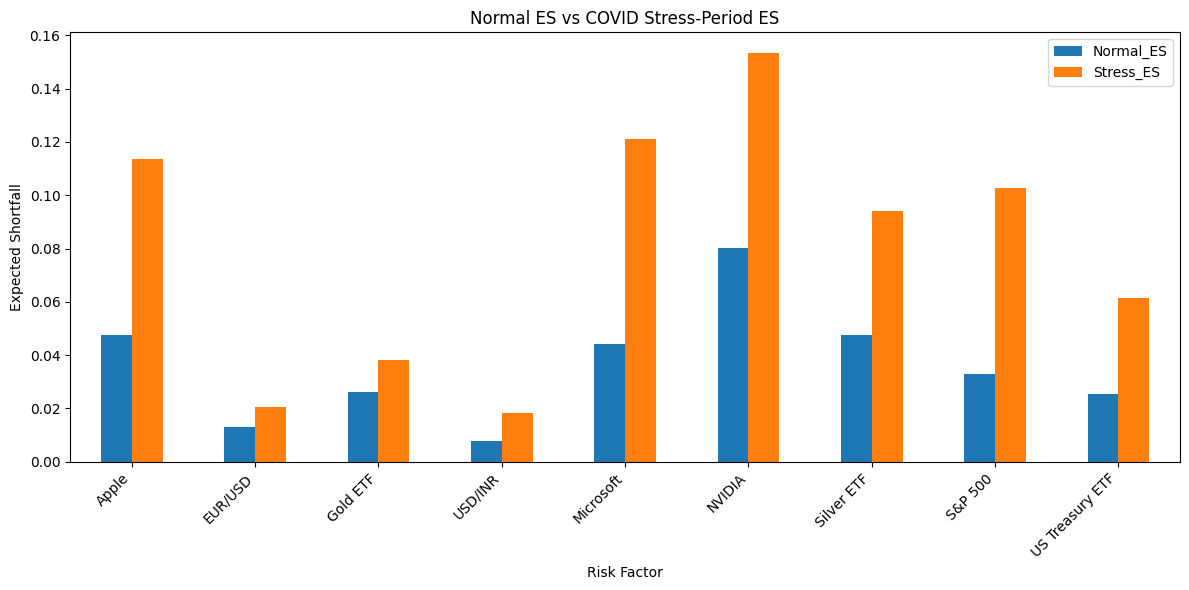

In [68]:
import matplotlib.pyplot as plt

stress_comparison.set_index("Risk_Factor")[
    ["Normal_ES", "Stress_ES"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Normal ES vs COVID Stress-Period ES")
plt.ylabel("Expected Shortfall")
plt.xlabel("Risk Factor")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Step 8 – Non-Modellable Risk Factors (NMRF) and SSRM

In [69]:
modellability_assessment = pd.DataFrame({
    "Risk_Factor": market_returns.columns,
    "Modellability_Status": [
        "MRF - Assumed",
        "MRF - Assumed",
        "MRF - Assumed",
        "MRF - Assumed",
        "MRF - Assumed",
        "MRF - Assumed",
        "NMRF - Assumed",
        "MRF - Assumed",
        "NMRF - Assumed"
    ]
})

print(modellability_assessment)

       Risk_Factor Modellability_Status
0            Apple        MRF - Assumed
1          EUR/USD        MRF - Assumed
2         Gold ETF        MRF - Assumed
3          USD/INR        MRF - Assumed
4        Microsoft        MRF - Assumed
5           NVIDIA        MRF - Assumed
6       Silver ETF       NMRF - Assumed
7          S&P 500        MRF - Assumed
8  US Treasury ETF       NMRF - Assumed


In [70]:
nmrf_factors = modellability_assessment.loc[
    modellability_assessment["Modellability_Status"] == "NMRF - Assumed",
    "Risk_Factor"
].tolist()

nmrf_ssrm = stress_summary[
    stress_summary["Risk_Factor"].isin(nmrf_factors)
].copy()

nmrf_ssrm = nmrf_ssrm[["Risk_Factor", "Stress_ES_97.5"]].rename(
    columns={"Stress_ES_97.5": "Illustrative_SSRM"}
)

print(nmrf_ssrm.round(5))

       Risk_Factor  Illustrative_SSRM
6       Silver ETF            0.09403
8  US Treasury ETF            0.06155


In [71]:
total_nmrf_ssrm = nmrf_ssrm["Illustrative_SSRM"].sum()

print(f"Total Illustrative NMRF SSRM: {total_nmrf_ssrm:.4%}")

nmrf_ssrm.to_csv(
    base_path / "outputs" / "nmrf_ssrm_summary.csv",
    index=False
)

Total Illustrative NMRF SSRM: 15.5581%


Step 9 – Default Risk Charge (DRC)

In [72]:
drc_trades = trade_book[
    trade_book["Product_Type"] == "Corporate Bond"
].copy()

print(drc_trades[[
    "Trade_ID", "Instrument", "Issuer",
    "Position", "Notional", "Market_Value"
]])

   Trade_ID        Instrument     Issuer Position  Notional  Market_Value
3     TR004  Corporate Bond A  Company A     Long    800000        780000
11    TR012  Corporate Bond B  Company B     Long    900000        875000


In [73]:
credit_ratings = pd.DataFrame({
    "Issuer": ["Company A", "Company B"],
    "Credit_Rating": ["BBB", "BB"],
    "LGD": [0.60, 0.60]
})

drc_trades = drc_trades.drop(
    columns=["Credit_Rating", "LGD"], errors="ignore"
)

drc_trades = drc_trades.merge(
    credit_ratings, on="Issuer", how="left"
)

print(drc_trades[[
    "Trade_ID", "Issuer", "Credit_Rating", "LGD"
]])

  Trade_ID     Issuer Credit_Rating  LGD
0    TR004  Company A           BBB  0.6
1    TR012  Company B            BB  0.6


In [74]:
drc_trades["Default_Exposure"] = drc_trades["Market_Value"]

drc_trades["Loss_Given_Default"] = (
    drc_trades["Default_Exposure"] * drc_trades["LGD"]
)

print(drc_trades[[
    "Trade_ID", "Issuer", "Default_Exposure",
    "LGD", "Loss_Given_Default"
]])

  Trade_ID     Issuer  Default_Exposure  LGD  Loss_Given_Default
0    TR004  Company A            780000  0.6            468000.0
1    TR012  Company B            875000  0.6            525000.0


In [75]:
pd_assumptions = pd.DataFrame({
    "Credit_Rating": ["BBB", "BB"],
    "One_Year_PD": [0.002, 0.01]
})

drc_trades = drc_trades.merge(
    pd_assumptions, on="Credit_Rating", how="left"
)

print(drc_trades[[
    "Trade_ID", "Issuer", "Credit_Rating",
    "One_Year_PD", "Loss_Given_Default"
]])

  Trade_ID     Issuer Credit_Rating  One_Year_PD  Loss_Given_Default
0    TR004  Company A           BBB        0.002            468000.0
1    TR012  Company B            BB        0.010            525000.0


In [76]:
import numpy as np

np.random.seed(42)

simulations = 100_000
default_losses = np.zeros(simulations)

for _, trade in drc_trades.iterrows():
    defaults = np.random.binomial(
        1, trade["One_Year_PD"], simulations
    )
    default_losses += defaults * trade["Loss_Given_Default"]

expected_loss = default_losses.mean()
drc_999 = np.quantile(default_losses, 0.999)

print(f"Average Simulated Loss: ${expected_loss:,.2f}")
print(f"99.9% Tail Loss: ${drc_999:,.2f}")

Average Simulated Loss: $6,213.96
99.9% Tail Loss: $525,000.00


In [77]:
drc_simulation_summary = pd.DataFrame({
    "Metric": ["Average Simulated Loss", "99.9% Tail Loss"],
    "Value": [expected_loss, drc_999]
})

drc_simulation_summary.to_csv(
    base_path / "outputs" / "drc_simulation_summary.csv",
    index=False
)

print(drc_simulation_summary)

                   Metric      Value
0  Average Simulated Loss    6213.96
1         99.9% Tail Loss  525000.00


Step 10 – FRTB-IMA Capital Aggregation

In [78]:
capital_components = pd.DataFrame({
    "Capital_Component": [
        "Historical ES (97.5%)",
        "Illustrative NMRF SSRM",
        "Illustrative DRC (99.9%)"
    ],
    "Risk_Measure": [
        historical_es,
        total_nmrf_ssrm,
        drc_999
    ],
    "Unit": [
        "Return",
        "Return",
        "USD"
    ],
    "Methodology": [
        "Equal-weighted historical ES",
        "Simplified stress ES proxy",
        "Independent-default simulation"
    ]
})

print(capital_components)

          Capital_Component   Risk_Measure    Unit  \
0     Historical ES (97.5%)       0.023043  Return   
1    Illustrative NMRF SSRM       0.155581  Return   
2  Illustrative DRC (99.9%)  525000.000000     USD   

                      Methodology  
0    Equal-weighted historical ES  
1      Simplified stress ES proxy  
2  Independent-default simulation  


In [79]:
capital_components.to_csv(
    base_path / "outputs" / "capital_components_summary.csv",
    index=False
)

print("Capital component summary saved successfully.")

Capital component summary saved successfully.


Step 11 – Backtesting

Prepare portfolio returns and rolling VaR

In [80]:
import numpy as np
import pandas as pd

weights = pd.Series(1 / len(market_returns.columns),
                    index=market_returns.columns)

portfolio_returns = market_returns.dot(weights)
portfolio_losses = -portfolio_returns

lookback = 250
confidence_level = 0.99

backtest_results = pd.DataFrame({
    "Actual_Loss": portfolio_losses
})

backtest_results["VaR_99"] = np.nan

for i in range(lookback, len(backtest_results)):
    historical_losses = portfolio_losses.iloc[i-lookback:i]
    backtest_results.iloc[i, backtest_results.columns.get_loc("VaR_99")] = (
        historical_losses.quantile(confidence_level)
    )

backtest_results = backtest_results.dropna()

print("Backtesting Dataset Shape:", backtest_results.shape)
print(backtest_results.head())

Backtesting Dataset Shape: (713, 2)
            Actual_Loss    VaR_99
Date                             
2023-01-19     0.003500  0.028261
2023-01-20    -0.013530  0.028261
2023-01-23    -0.010896  0.028261
2023-01-24    -0.004892  0.028261
2023-01-25    -0.001348  0.028261


Step 11.2 – Identify VaR Exceptions

In [81]:
backtest_results["Exception"] = (
    backtest_results["Actual_Loss"] > backtest_results["VaR_99"]
)

exception_count = backtest_results["Exception"].sum()
total_observations = len(backtest_results)

exception_rate = exception_count / total_observations

print("Total Observations:", total_observations)
print("VaR Exceptions:", exception_count)
print(f"Exception Rate: {exception_rate:.2%}")

Total Observations: 713
VaR Exceptions: 9
Exception Rate: 1.26%


Step 11.3 – Evaluate Backtesting Performance

In [82]:
expected_exception_rate = 0.01
expected_exceptions = total_observations * expected_exception_rate

if exception_rate <= expected_exception_rate:
    backtest_status = "Within Expected Exception Rate"
else:
    backtest_status = "Above Expected Exception Rate"

backtest_summary = pd.DataFrame({
    "Metric": [
        "Total Observations",
        "Observed Exceptions",
        "Expected Exceptions",
        "Observed Exception Rate",
        "Expected Exception Rate",
        "Assessment"
    ],
    "Value": [
        total_observations,
        exception_count,
        round(expected_exceptions, 2),
        f"{exception_rate:.2%}",
        "1.00%",
        backtest_status
    ]
})

print(backtest_summary)

                    Metric                          Value
0       Total Observations                            713
1      Observed Exceptions                              9
2      Expected Exceptions                           7.13
3  Observed Exception Rate                          1.26%
4  Expected Exception Rate                          1.00%
5               Assessment  Above Expected Exception Rate


Step 11.4 – Visualize VaR versus actual losses

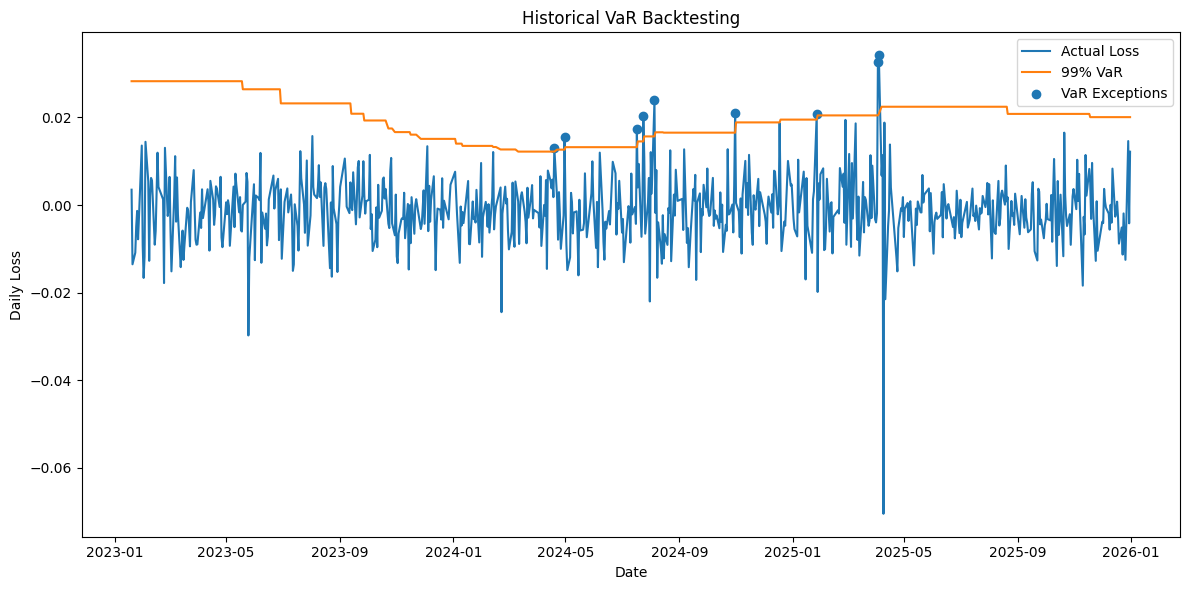

In [83]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    backtest_results.index,
    backtest_results["Actual_Loss"],
    label="Actual Loss"
)

plt.plot(
    backtest_results.index,
    backtest_results["VaR_99"],
    label="99% VaR"
)

plt.scatter(
    backtest_results.index[backtest_results["Exception"]],
    backtest_results.loc[backtest_results["Exception"], "Actual_Loss"],
    label="VaR Exceptions"
)

plt.title("Historical VaR Backtesting")
plt.xlabel("Date")
plt.ylabel("Daily Loss")
plt.legend()
plt.tight_layout()
plt.show()

Step 11.5 – Export the backtesting reports

In [84]:
backtest_results.to_csv(
    base_path / "outputs" / "backtesting_results.csv"
)

backtest_summary.to_csv(
    base_path / "outputs" / "backtesting_summary.csv",
    index=False
)

print("Backtesting reports exported successfully.")

Backtesting reports exported successfully.


Step 12 – P&L Attribution Test (PLAT)

In [85]:
print("Available backtesting columns:")
print(backtest_results.columns.tolist())

print("\nPortfolio return observations:", len(portfolio_returns))
print("Risk factor columns:", market_returns.columns.tolist())
print("\nTrade book columns:")
print(trade_book.columns.tolist())

Available backtesting columns:
['Actual_Loss', 'VaR_99', 'Exception']

Portfolio return observations: 963
Risk factor columns: ['Apple', 'EUR/USD', 'Gold ETF', 'USD/INR', 'Microsoft', 'NVIDIA', 'Silver ETF', 'S&P 500', 'US Treasury ETF']

Trade book columns:
['Trade_ID', 'Instrument', 'Asset_Class', 'Product_Type', 'Position', 'Notional', 'Market_Value', 'Currency', 'Issuer', 'Maturity', 'Option_Type']


Step 12.2 – Construct HPL (Hypothetical P&L)

In [86]:
hpl_exposures = {
    "Apple": 500000,
    "Microsoft": 300000,
    "Gold ETF": 400000,
    "Silver ETF": -300000
}

hpl = pd.Series(0.0, index=market_returns.index)

for factor, exposure in hpl_exposures.items():
    hpl += market_returns[factor] * exposure

print(hpl.head())

Date
2022-01-04   -10526.404217
2022-01-05   -21516.359880
2022-01-06    -8614.883160
2022-01-07      858.727339
2022-01-10     -543.157773
dtype: float64


Step 12.3 – Construct RTPL (Risk-Theoretical P&L)

In [87]:
# Delta sensitivities
rtpl_sensitivities = {
    "Apple": 490000,
    "Microsoft": 285000,
    "Gold ETF": 390000,
    "Silver ETF": -290000
}

# Illustrative curvature assumptions
curvature_sensitivities = {
    "Apple": 2000000,
    "Microsoft": 1000000,
    "Gold ETF": 1500000,
    "Silver ETF": -1000000
}

rtpl = pd.Series(0.0, index=market_returns.index)

for factor, sensitivity in rtpl_sensitivities.items():
    returns = market_returns[factor]

    # Linear Delta P&L
    delta_pnl = sensitivity * returns

    # Nonlinear Curvature P&L
    gamma = curvature_sensitivities[factor]
    curvature_pnl = 0.5 * gamma * returns**2

    rtpl += delta_pnl + curvature_pnl

print(rtpl.head())

Date
2022-01-04    -9822.897918
2022-01-05   -19456.077468
2022-01-06    -8290.209593
2022-01-07      851.574493
2022-01-10     -533.642295
dtype: float64


Step 12.4 – Compare HPL and RTPL

In [88]:
plat_comparison = pd.DataFrame({
    "HPL": hpl,
    "RTPL": rtpl
})

plat_comparison["P&L_Difference"] = (
    plat_comparison["HPL"] - plat_comparison["RTPL"]
)

plat_correlation = plat_comparison["HPL"].corr(
    plat_comparison["RTPL"]
)

print("HPL vs RTPL Correlation:", round(plat_correlation, 4))
print("\nP&L Comparison:")
print(plat_comparison.head())

HPL vs RTPL Correlation: 0.9952

P&L Comparison:
                     HPL          RTPL  P&L_Difference
Date                                                  
2022-01-04 -10526.404217  -9822.897918     -703.506299
2022-01-05 -21516.359880 -19456.077468    -2060.282412
2022-01-06  -8614.883160  -8290.209593     -324.673567
2022-01-07    858.727339    851.574493        7.152845
2022-01-10   -543.157773   -533.642295       -9.515478


Step 13 – Final FRTB-IMA Project Summary and Reporting

In [89]:
final_summary = pd.DataFrame([
    ["Historical ES (97.5%)", f"{historical_es:.4%}", "Equal-weighted historical portfolio proxy"],
    ["Maximum Stress ES", f"{stress_summary['Stress_ES_97.5'].max():.4%}", "Illustrative COVID stress-period analysis"],
    ["NMRF SSRM", f"{total_nmrf_ssrm:.4%}", "Simplified stress ES proxy"],
    ["DRC 99.9% Tail Loss", f"${drc_999:,.2f}", "Independent-default simulation"],
    ["Backtesting Exceptions", f"{exception_count} ({exception_rate:.2%})", "Rolling 250-day VaR comparison"],
    ["PLAT Correlation", f"{plat_correlation:.4f}", "Illustrative HPL vs RTPL comparison"]
], columns=["Project_Area", "Result", "Methodology"])

final_summary.to_csv(
    base_path / "outputs" / "final_ima_project_summary.csv",
    index=False
)

print(final_summary.to_string(index=False))

          Project_Area      Result                               Methodology
 Historical ES (97.5%)     2.3043% Equal-weighted historical portfolio proxy
     Maximum Stress ES    15.3444% Illustrative COVID stress-period analysis
             NMRF SSRM    15.5581%                Simplified stress ES proxy
   DRC 99.9% Tail Loss $525,000.00            Independent-default simulation
Backtesting Exceptions   9 (1.26%)            Rolling 250-day VaR comparison
      PLAT Correlation      0.9952       Illustrative HPL vs RTPL comparison
